# Humidity, pressure, and soil moisture: EDA, cleaning, and preparation

Read `raw_dataset/3_humidity_pressure_soil.csv`, explore the original data, clean and prepare the fields, explore the prepared data, then save the result in `clean_dataset/humidity_pressure_soil_clean.csv`.

In [8]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
SOURCE_FILE = '3_humidity_pressure_soil.csv'
OUTPUT_FILE = 'humidity_pressure_soil_clean.csv'
DATASET_TITLE = 'Humidity, pressure, and soil moisture'
MEASUREMENT_COLUMNS = ['rh_pct', 'q_gkg', 'temp_c', 'dewpoint_c', 'pressure_hpa', 'pressure_hpa_before', 'pressure_hpa_after', 'pressure_chg_hpa', 'rh_pct_before', 'rh_pct_after', 'rh_chg_pct', 'soil_l1', 'soil_l2', 'soil_l3', 'soil_l4', 'soil_l1_before', 'soil_l1_after', 'soil_l1_chg']
PLOT_COLUMNS = ['rh_pct', 'temp_c', 'pressure_hpa', 'soil_l1']
HAS_DATE = True
SPECIAL_DATASET = ''
KEY_COLUMNS = ["date", "unit_level", "district_code"] if HAS_DATE else ["unit_level", "district_code"]

project_dir = next(
    (path for path in [Path.cwd(), *Path.cwd().parents]
     if (path / "raw_dataset" / SOURCE_FILE).is_file()),
    None,
)
if project_dir is None:
    raise FileNotFoundError(f"Cannot find raw_dataset/{SOURCE_FILE} from {Path.cwd()}")
source_path = project_dir / "raw_dataset" / SOURCE_FILE
raw_df = pd.read_csv(source_path, encoding="utf-8-sig")
required_columns = set(KEY_COLUMNS + MEASUREMENT_COLUMNS)
missing_columns = sorted(required_columns - set(raw_df.columns))
if missing_columns:
    raise ValueError(f"Required columns missing from {SOURCE_FILE}: {missing_columns}")


def show_eda(frame, stage):
    print(f"{stage}: {len(frame):,} rows x {len(frame.columns)} columns")
    if HAS_DATE:
        dates = pd.to_datetime(frame["date"], errors="coerce")
        print(f"Date range: {dates.min().date()} to {dates.max().date()}")
    available_measurements = [column for column in MEASUREMENT_COLUMNS if column in frame.columns]
    missing = frame[available_measurements].isna().mean().mul(100).sort_values()
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    missing.tail(15).plot(kind="barh", ax=axes[0], color="darkorange")
    axes[0].set(title=f"{stage}: missing measurements", xlabel="Missing (%)")
    if HAS_DATE:
        plot_cols = [column for column in PLOT_COLUMNS if column in frame.columns]
        date_frame = frame.assign(date=pd.to_datetime(frame["date"], errors="coerce"))
        monthly = date_frame.dropna(subset=["date"]).set_index("date")[plot_cols].resample("MS").mean()
        monthly.plot(ax=axes[1])
        axes[1].set(title=f"{stage}: monthly measurements", xlabel="Date")
        axes[1].legend(fontsize=8)
    else:
        if {"lon", "lat", "elevation_m"}.issubset(frame.columns):
            sns.scatterplot(data=frame, x="lon", y="lat", hue="elevation_m", palette="viridis", ax=axes[1])
            axes[1].set_title(f"{stage}: elevation by location")
        else:
            axes[1].axis("off")
    plt.tight_layout()
    plt.show()

    plot_cols = [column for column in PLOT_COLUMNS if column in frame.columns]
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    for column, ax in zip(plot_cols, axes.flat):
        sns.histplot(data=frame, x=column, bins=35, kde=True, ax=ax, color="teal")
        ax.set_title(f"{stage}: {column}")
    for ax in axes.flat[len(plot_cols):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


In [9]:
print(f"Source: {source_path}")
print("Rows by unit level:")
display(raw_df["unit_level"].value_counts(dropna=False).to_frame("rows"))
print("Data types:")
display(raw_df.dtypes.astype(str).rename("dtype").to_frame())
print("Sample:")
display(raw_df.head())


Source: c:\Users\sitti\OneDrive\Desktop\Nahh ahhh v4\raw_dataset\3_humidity_pressure_soil.csv
Rows by unit level:


,rows
unit_level,
amphoe,39456
province,2192


Data types:


,dtype
date,object
year,int64
month,int64
day,int64
doy,int64
unit_level,object
province,object
district,object
district_code,int64
rh_pct,float64


Sample:


,date,year,month,day,doy,unit_level,province,district,district_code,rh_pct,...,rh_pct_before,rh_pct_after,rh_chg_pct,soil_l1,soil_l2,soil_l3,soil_l4,soil_l1_before,soil_l1_after,soil_l1_chg
0,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Bang Khan,26738,76.307780,...,85.803362,94.213753,8.410391,0.314444,0.363775,0.401282,0.463076,0.321795,0.312548,-0.009247
1,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Cha-uat,26739,79.853417,...,84.955235,93.665580,8.710345,0.358228,0.374952,0.426835,0.425819,0.363115,0.358640,-0.004475
2,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Chawang,26740,78.700284,...,96.296583,98.548438,2.251855,0.274673,0.317321,0.364388,0.433261,0.283184,0.272302,-0.010882
3,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Chian Yai,26741,79.453891,...,84.058379,91.298861,7.240482,0.423874,0.407663,0.450198,0.477605,0.431771,0.421236,-0.010534
4,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Hua Sai,26742,76.597424,...,79.087888,84.865125,5.777236,0.371052,0.383710,0.433262,0.468264,0.378544,0.370954,-0.007590


## 1. EDA on the original data

Missing measurements:


,missing_rows
rh_pct,2192
q_gkg,2192
temp_c,2192
dewpoint_c,2192
pressure_hpa,2192
pressure_hpa_before,2192
pressure_hpa_after,2192
pressure_chg_hpa,2192
rh_pct_before,2192
rh_pct_after,2192


Exact duplicate rows: 0
Duplicate key rows: 0
Measurement summary:


,count,mean,std,min,25%,50%,75%,max
rh_pct,39456.0,82.7709,7.5428,48.7664,78.6293,83.5468,88.0600,99.3535
q_gkg,39456.0,17.6833,1.2008,10.9576,17.0961,17.9460,18.4763,21.7743
temp_c,39456.0,26.1848,1.4918,21.5187,25.1590,26.0931,27.1230,32.1116
dewpoint_c,39456.0,22.9443,1.2006,14.9458,22.3458,23.2110,23.7571,26.6135
pressure_hpa,39456.0,995.8192,11.7588,967.0825,990.4736,998.4445,1005.7495,1015.4054
pressure_hpa_before,39456.0,996.0696,11.8095,966.5874,990.7068,998.7243,1006.0296,1015.5365
pressure_hpa_after,39456.0,995.5368,11.8034,966.4507,990.1825,998.1889,1005.4777,1014.7900
pressure_chg_hpa,39456.0,-0.5328,0.8560,-3.2917,-1.1216,-0.5413,0.0230,2.8108
rh_pct_before,39456.0,94.1447,3.8775,64.7891,92.2632,95.0323,96.9885,99.8244
rh_pct_after,39456.0,94.4962,3.8667,65.5735,92.5745,95.3232,97.2949,99.9268


Original data: 41,648 rows x 27 columns
Date range: 2020-01-01 to 2025-12-31


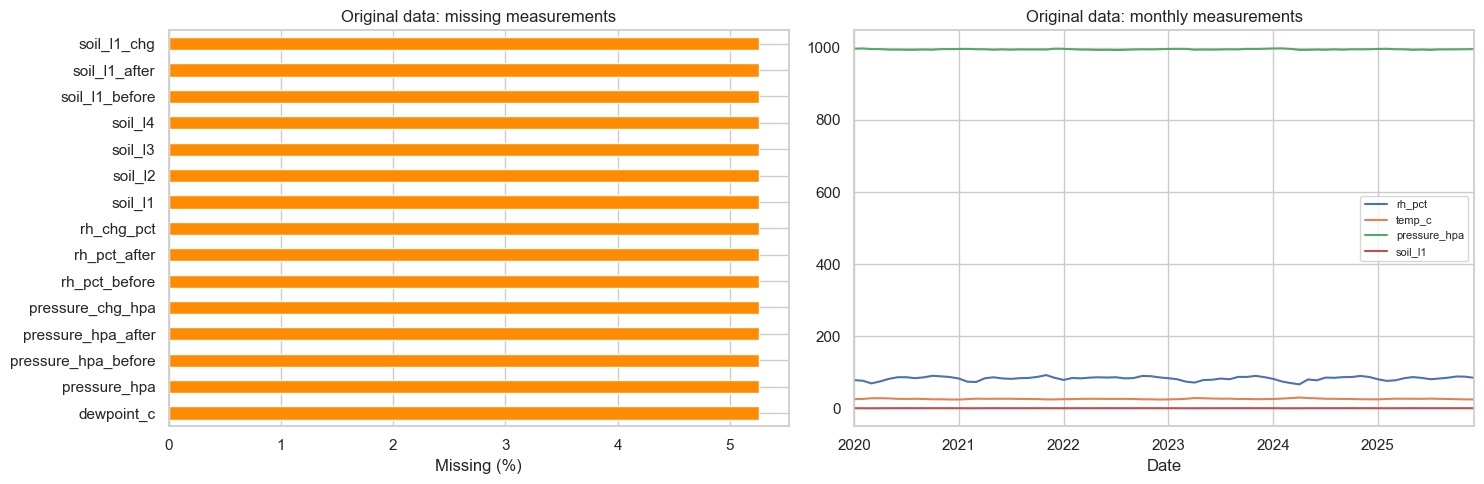

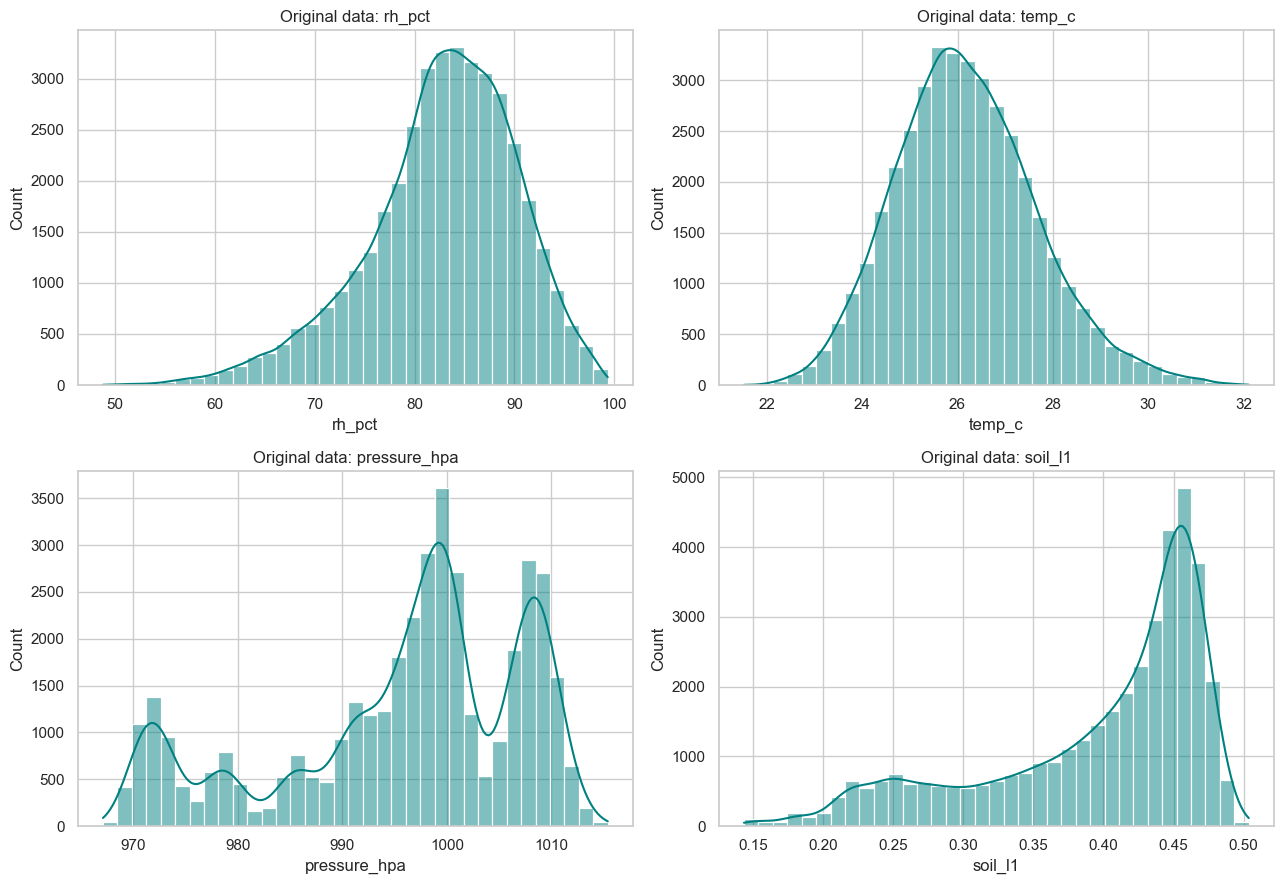

In [10]:
eda_df = raw_df.copy()
if HAS_DATE:
    eda_df["date"] = pd.to_datetime(eda_df["date"], errors="coerce")
print("Missing measurements:")
display(eda_df[MEASUREMENT_COLUMNS].isna().sum().sort_values(ascending=False).rename("missing_rows").to_frame())
print("Exact duplicate rows:", int(eda_df.duplicated().sum()))
print("Duplicate key rows:", int(eda_df.duplicated(KEY_COLUMNS).sum()))
print("Measurement summary:")
display(eda_df[MEASUREMENT_COLUMNS].describe().T.round(4))
show_eda(eda_df, "Original data")


## 2. Clean the data

Normalize dates, text and numeric types, and remove invalid keys or duplicate records. Keep missing source measurements intact; do not treat unavailable observations as zero.

In [11]:
df_clean = raw_df.copy()
rows_before = len(df_clean)
if HAS_DATE:
    df_clean["date"] = pd.to_datetime(df_clean["date"], errors="coerce")

text_columns = df_clean.select_dtypes(include=["object", "string"]).columns
for column in text_columns:
    df_clean[column] = (df_clean[column].astype("string").str.strip()
                        .str.replace(r"\s+", " ", regex=True))
df_clean["district_code"] = pd.to_numeric(df_clean["district_code"], errors="coerce")
for column in MEASUREMENT_COLUMNS:
    df_clean[column] = pd.to_numeric(df_clean[column], errors="coerce")

df_clean = df_clean.dropna(subset=KEY_COLUMNS).copy()
df_clean["district_code"] = df_clean["district_code"].astype("int64")
df_clean = df_clean.drop_duplicates()
df_clean = df_clean.drop_duplicates(subset=KEY_COLUMNS, keep="first")
print(f"Rows before cleaning: {rows_before:,}")
print(f"Rows after cleaning: {len(df_clean):,}")
print(f"Rows removed: {rows_before - len(df_clean):,}")
print("Remaining missing measurements (not imputed):")
display(df_clean[MEASUREMENT_COLUMNS].isna().sum().sort_values(ascending=False).rename("missing_rows").to_frame())
display(df_clean.head())


Rows before cleaning: 41,648
Rows after cleaning: 41,648
Rows removed: 0
Remaining missing measurements (not imputed):


,missing_rows
rh_pct,2192
q_gkg,2192
temp_c,2192
dewpoint_c,2192
pressure_hpa,2192
pressure_hpa_before,2192
pressure_hpa_after,2192
pressure_chg_hpa,2192
rh_pct_before,2192
rh_pct_after,2192


,date,year,month,day,doy,unit_level,province,district,district_code,rh_pct,...,rh_pct_before,rh_pct_after,rh_chg_pct,soil_l1,soil_l2,soil_l3,soil_l4,soil_l1_before,soil_l1_after,soil_l1_chg
0,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Bang Khan,26738,76.307780,...,85.803362,94.213753,8.410391,0.314444,0.363775,0.401282,0.463076,0.321795,0.312548,-0.009247
1,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Cha-uat,26739,79.853417,...,84.955235,93.665580,8.710345,0.358228,0.374952,0.426835,0.425819,0.363115,0.358640,-0.004475
2,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Chawang,26740,78.700284,...,96.296583,98.548438,2.251855,0.274673,0.317321,0.364388,0.433261,0.283184,0.272302,-0.010882
3,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Chian Yai,26741,79.453891,...,84.058379,91.298861,7.240482,0.423874,0.407663,0.450198,0.477605,0.431771,0.421236,-0.010534
4,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Hua Sai,26742,76.597424,...,79.087888,84.865125,5.777236,0.371052,0.383710,0.433262,0.468264,0.378544,0.370954,-0.007590


## 3. Prepare the data

Add missing-data indicators where source measurements are missing, rebuild calendar fields where applicable, sort by the dataset keys, and preserve the original measurements without imputation.

In [12]:
df_prepared = df_clean.copy()
required_columns = set(KEY_COLUMNS)
all_empty_columns = [column for column in df_prepared.columns
                     if column not in required_columns and df_prepared[column].isna().all()]
df_prepared = df_prepared.drop(columns=all_empty_columns)

flagged_columns = [column for column in MEASUREMENT_COLUMNS
                   if column in df_prepared.columns and df_prepared[column].isna().any()]
for column in flagged_columns:
    df_prepared[f"{column}_missing"] = df_prepared[column].isna().astype("int8")

if SPECIAL_DATASET == "flood":
    df_prepared["flood_obs_available"] = df_prepared["flood_obs"].notna().astype("int8")
    if not df_prepared["flood_obs"].dropna().isin([0, 1]).all():
        raise ValueError("flood_obs must contain only 0, 1, or missing values")
elif SPECIAL_DATASET == "river":
    df_prepared["river_observation_available"] = df_prepared["n_scenes"].gt(0).astype("int8")

if HAS_DATE:
    df_prepared["year"] = df_prepared["date"].dt.year.astype("int16")
    df_prepared["month"] = df_prepared["date"].dt.month.astype("int8")
    df_prepared["day"] = df_prepared["date"].dt.day.astype("int8")
    df_prepared["doy"] = df_prepared["date"].dt.dayofyear.astype("int16")

df_prepared = df_prepared.sort_values(KEY_COLUMNS).reset_index(drop=True)
assert df_prepared[KEY_COLUMNS].notna().all().all()
assert not df_prepared.duplicated(KEY_COLUMNS).any()
print(f"Prepared shape: {df_prepared.shape}")
print(f"All-empty columns removed: {all_empty_columns}")
print(f"Missing-indicator columns added: {flagged_columns}")
print("Missing measurements remain available for review; no values were imputed.")


Prepared shape: (41648, 45)
All-empty columns removed: []
Missing-indicator columns added: ['rh_pct', 'q_gkg', 'temp_c', 'dewpoint_c', 'pressure_hpa', 'pressure_hpa_before', 'pressure_hpa_after', 'pressure_chg_hpa', 'rh_pct_before', 'rh_pct_after', 'rh_chg_pct', 'soil_l1', 'soil_l2', 'soil_l3', 'soil_l4', 'soil_l1_before', 'soil_l1_after', 'soil_l1_chg']
Missing measurements remain available for review; no values were imputed.


## 4. EDA on the cleaned and prepared data

Prepared data types:


,dtype
date,datetime64[ns]
year,int16
month,int8
day,int8
doy,int16
unit_level,string
province,string
district,string
district_code,int64
rh_pct,float64


Prepared measurement summary:


,count,mean,std,min,25%,50%,75%,max
rh_pct,39456.0,82.7709,7.5428,48.7664,78.6293,83.5468,88.0600,99.3535
q_gkg,39456.0,17.6833,1.2008,10.9576,17.0961,17.9460,18.4763,21.7743
temp_c,39456.0,26.1848,1.4918,21.5187,25.1590,26.0931,27.1230,32.1116
dewpoint_c,39456.0,22.9443,1.2006,14.9458,22.3458,23.2110,23.7571,26.6135
pressure_hpa,39456.0,995.8192,11.7588,967.0825,990.4736,998.4445,1005.7495,1015.4054
pressure_hpa_before,39456.0,996.0696,11.8095,966.5874,990.7068,998.7243,1006.0296,1015.5365
pressure_hpa_after,39456.0,995.5368,11.8034,966.4507,990.1825,998.1889,1005.4777,1014.7900
pressure_chg_hpa,39456.0,-0.5328,0.8560,-3.2917,-1.1216,-0.5413,0.0230,2.8108
rh_pct_before,39456.0,94.1447,3.8775,64.7891,92.2632,95.0323,96.9885,99.8244
rh_pct_after,39456.0,94.4962,3.8667,65.5735,92.5745,95.3232,97.2949,99.9268


Missing values by prepared column:


,missing_rows
dewpoint_c,2192
rh_pct,2192
q_gkg,2192
temp_c,2192
soil_l2,2192
soil_l1,2192
rh_chg_pct,2192
rh_pct_after,2192
rh_pct_before,2192
pressure_chg_hpa,2192


Cleaned and prepared data: 41,648 rows x 45 columns
Date range: 2020-01-01 to 2025-12-31


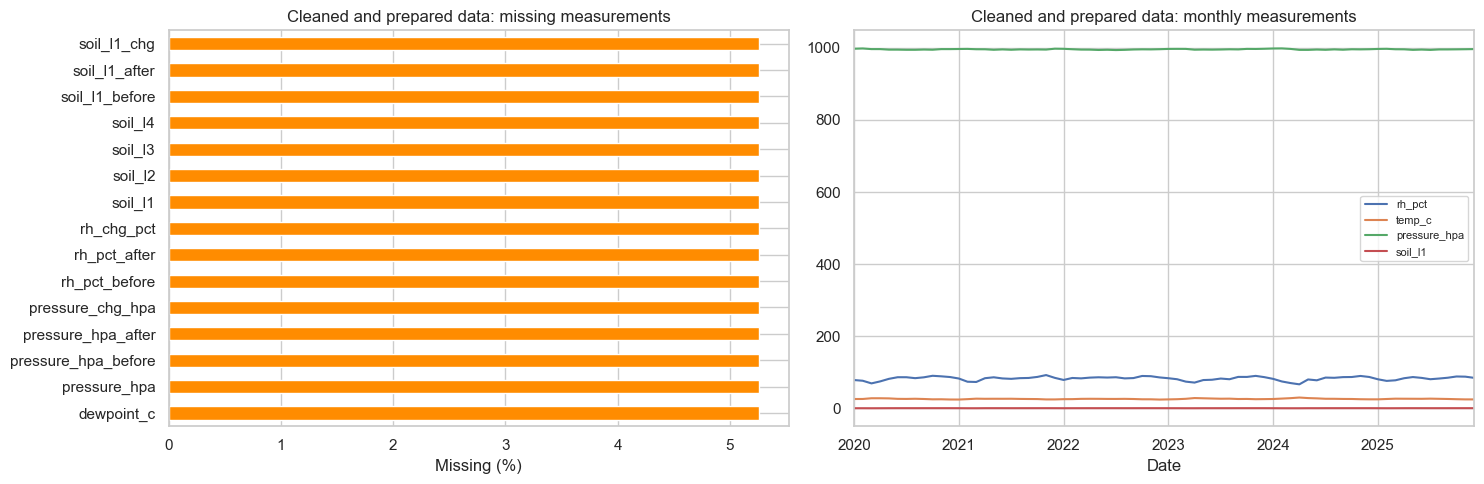

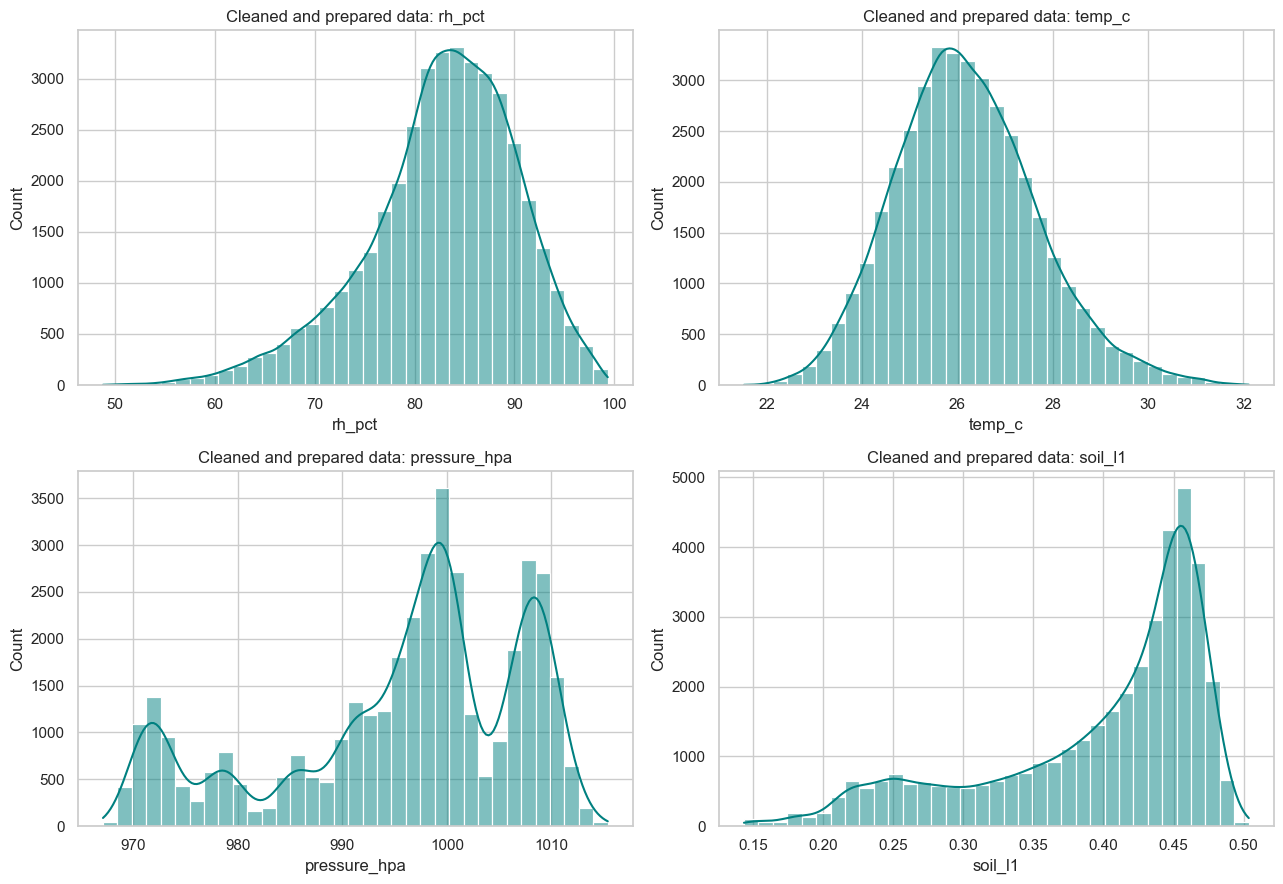

In [13]:
print("Prepared data types:")
display(df_prepared.dtypes.astype(str).rename("dtype").to_frame())
print("Prepared measurement summary:")
remaining_measurements = [column for column in MEASUREMENT_COLUMNS if column in df_prepared.columns]
display(df_prepared[remaining_measurements].describe().T.round(4))
print("Missing values by prepared column:")
display(df_prepared.isna().sum().sort_values(ascending=False).head(20).rename("missing_rows").to_frame())
show_eda(df_prepared, "Cleaned and prepared data")


## 5. Save the prepared data

In [14]:
output_dir = project_dir / "clean_dataset"
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / OUTPUT_FILE
df_prepared.to_csv(output_path, index=False, date_format="%Y-%m-%d", encoding="utf-8-sig")

read_options = {"encoding": "utf-8-sig"}
if HAS_DATE:
    read_options["parse_dates"] = ["date"]
saved_df = pd.read_csv(output_path, **read_options)
assert saved_df.shape == df_prepared.shape
assert not saved_df.duplicated(KEY_COLUMNS).any()
print(f"Saved: {output_path}")
print(f"File size: {output_path.stat().st_size:,} bytes")
print(f"CSV shape: {saved_df.shape}")


Saved: c:\Users\sitti\OneDrive\Desktop\Nahh ahhh v4\clean_dataset\humidity_pressure_soil_clean.csv
File size: 18,490,504 bytes
CSV shape: (41648, 45)
